# Book Genre Analysis: A Project of Data Curation and Analysis
Ipek Coskunuzer


## Description
I collected book record data from the Open Library API to compare page counts across romance, fantasy, and mystery. I started with 600 book records and removed 10 with missing page counts, leaving 590. Furthermore, I found that there were 4 duplicate book IDs across the genres, but since one book can belong to multiple genres, I left the IDs in their respective categories. I organized the data into a table, checked for duplicates, and saved the cleaned data as a CSV. After calculating descriptive statistics and making box plots, I found that fantasy had the highest median page count at 440 pages, followed by mystery at 248 and romance at 191.

In [ ]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import json
import time
from datetime import datetime, timezone

## Step 1: Data Extraction
I used Python's "requests" to extract book record data from the
open library search API. I requested titles, authors, first publication
years, book IDs, and median page counts across editions.

API documentation: https://openlibrary.org/dev/docs/api/search

I collected the data on October 2, 2026. I used the first 200 results returned by Open Library for each genre with its default ordering.

In [ ]:
books_url = "https://openlibrary.org/search.json"

## Romance Books

search = {
    "subject": "romance",
    "limit": 200,
    "fields": "key,title,author_name,first_publish_year,number_of_pages_median"
}

opened_webpage = requests.get(books_url, params=search)
opened_webpage.raise_for_status()

romance_data = opened_webpage.json()

print(romance_data["docs"][0])

{'author_name': ['Zana Kheiron'], 'first_publish_year': 2019, 'key': '/works/OL35351151W', 'number_of_pages_median': 160, 'title': 'Um casamento arranjado'}


In [ ]:
## Fantasy Books

search = {
    "subject": "fantasy",
    "limit": 200,
    "fields": "key,title,author_name,first_publish_year,number_of_pages_median"
}

opened_webpage = requests.get(books_url, params=search)
opened_webpage.raise_for_status()

fantasy_data = opened_webpage.json()

print(fantasy_data["docs"][0])

{'author_name': ['Joe Abercrombie'], 'first_publish_year': 2001, 'key': '/works/OL8400950W', 'number_of_pages_median': 531, 'title': 'The Blade Itself'}


In [ ]:
## Mystery Books


search = {
    "subject": "mystery",
    "limit": 200,
    "fields": "key,title,author_name,first_publish_year,number_of_pages_median"
}

opened_webpage = requests.get(books_url, params=search)
opened_webpage.raise_for_status()

mystery_data = opened_webpage.json()

print(mystery_data["docs"][0])

{'author_name': ['Agatha Christie'], 'first_publish_year': 1932, 'key': '/works/OL472165W', 'number_of_pages_median': 223, 'title': 'Peril at End House'}


In [ ]:
print("Romance:", len(romance_data["docs"]))
print("Fantasy:", len(fantasy_data["docs"]))
print("Mystery:", len(mystery_data["docs"]))
print("Total Records:", len(romance_data["docs"]) + len(fantasy_data["docs"]) + len(mystery_data["docs"]))

Romance: 200
Fantasy: 200
Mystery: 200
Total Records: 600


### Saving the Raw Data
I collected 200 records for each genre: romance, fantasy, and mystery. Total of 600 book records. I saved the original API responses in a JSON file before cleaning so that I can return to the original data.

In [ ]:
# saving the raw data (uncleaned) into a dictionary "Raw Data"
raw_data = {
    "romance": romance_data,
    "fantasy": fantasy_data,
    "mystery": mystery_data
}

# writing the content into a file
with open("raw_books.json", "w") as file:
    json.dump(raw_data, file, indent=4)

print("Raw data saved.")

Raw data saved.


## Step 2: Data Transformation
I combined the three book genre searches into one table. The columns are: book ID, title, author(s), search genre, first publication year,
and median page count across editions. A book may appear in more
than one genre search, and that is why I also checked for duplicates during the cleaning and transformation!

In [ ]:
book_rows = []

# going through each genre and retrieving the relevant info + appending to the empty list book_rows
for genre in raw_data:
    for book in raw_data[genre]["docs"]:
        row = [
            book.get("key"),
            book.get("title"),
            ", ".join(book.get("author_name", [])),
            genre,
            book.get("first_publish_year"),
            book.get("number_of_pages_median")
        ]
        book_rows.append(row)

# columns for the table
column_names = [
    "book_id", "title", "authors", "genre",
    "first_publish_year", "page_count"
]

# creating the table
books_df = pd.DataFrame(book_rows, columns=column_names)

# first five rows
books_df.head()

,book_id,title,authors,genre,first_publish_year,page_count
0,/works/OL35351151W,Um casamento arranjado,Zana Kheiron,romance,2019,160.0
1,/works/OL25515697W,Twisted Games,Ana Huang,romance,2021,454.0
2,/works/OL24390422W,Twisted Love,Ana Huang,romance,2021,358.0
3,/works/OL27245843W,Twisted Hate,Ana Huang,romance,2022,576.0
4,/works/OL35223328W,Married at first sight,Gu Lingfei,romance,2015,NaN


In [ ]:
# checking for missing values and duplicate book IDs

print("Total rows:", len(books_df))

# checking for the missing values in all the columns besides the author column because isna doesn't account for empty strings
print("Missing values per column:")
print(books_df.isna().sum())

# checking the author column for missing values
print("Blank author entries:")
print((books_df["authors"] == "").sum())

# checking for duplicate book ids
print("Repeated book IDs:")
print(books_df.duplicated(subset="book_id").sum())

Total rows: 600
Missing values per column:
book_id                0
title                  0
authors                0
genre                  0
first_publish_year     0
page_count            10
dtype: int64
Blank author entries:
0
Repeated book IDs:
4


### Data Cleaning
After going through the checking for missing values process, I concluded that **10 book records** have missing page counts, and I excluded these records because their book lengths cannot be taken into account, so they don't contribute to my analysis. I also checked for duplicate records using both book ID and genre, and there are **4 repeated book ids**, and because one book can belong to multiple genres, I chose to just leave them in each group.

In [ ]:
# creating a "cleaned" table called clean_books, removing rows with missing page counts
clean_books = books_df.dropna(subset=["page_count"])

# removing rows where both the book ID and genre match
clean_books = clean_books.drop_duplicates(subset=["book_id", "genre"])

print("Rows before cleaning:", len(books_df))
print("Rows after cleaning:", len(clean_books))
print("Books remaining by", clean_books ["genre"].value_counts())

Rows before cleaning: 600
Rows after cleaning: 590
Books remaining by genre
fantasy    199
mystery    199
romance    192
Name: count, dtype: int64


### Saving the Processed Data
After cleaning, 590 book  records remain: 199 fantasy,
199 mystery, and 192 romance. I saved this processed table as a CSV
with column headers.

In [ ]:
clean_books.to_csv("book_page_counts.csv", index=False)

print("book_page_counts.csv saved.")

book_page_counts.csv saved.


## Step 3: Analysis — summary and visualizations

I calculated the descriptive statistics for both numerical columns:
first publication year and page count. The results include the
mean, median, and standard deviation. These summaries describe book–genre records, so books appearing in multiple genres contribute more than once.

In [ ]:
clean_books[["first_publish_year", "page_count"]].describe()

,first_publish_year,page_count
count,590.000000,590.000000
mean,1980.676271,340.730508
std,40.045669,191.867509
min,1583.000000,42.000000
25%,1973.250000,192.000000
50%,1988.000000,270.000000
75%,2005.000000,411.250000
max,2025.000000,1456.000000


In [ ]:
clean_books.groupby("genre")["page_count"].describe()

,count,mean,std,min,25%,50%,75%,max
genre,,,,,,,,
fantasy,199.0,502.482412,218.054364,42.0,351.5,440.0,636.50,1456.0
mystery,199.0,271.130653,101.879474,42.0,212.5,248.0,320.00,922.0
romance,192.0,245.218750,109.527610,106.0,188.0,191.0,239.25,739.0


### Page Counts by Genre
I used box plots to compare the median, spread, and potential outliers of page counts across the three genre groups because I had a numerical variable (page count) and a categorical variable (the three genres) and wanted to compare distributions within each genre.

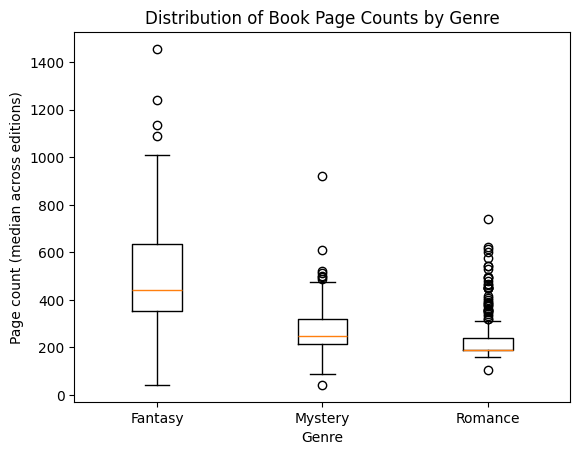

In [ ]:
fantasy_pages = clean_books[clean_books["genre"] == "fantasy"]["page_count"]
mystery_pages = clean_books[clean_books["genre"] == "mystery"]["page_count"]
romance_pages = clean_books[clean_books["genre"] == "romance"]["page_count"]

plt.boxplot([fantasy_pages, mystery_pages, romance_pages])

plt.xticks([1, 2, 3], ["Fantasy", "Mystery", "Romance"])
plt.xlabel("Genre")
plt.ylabel("Page count (median across editions)")
plt.title("Distribution of Book Page Counts by Genre")

plt.show()

After calculating the descriptive statistics and visualizing the box plots, I found that fantasy books generally have higher page counts than mystery and romance books in the collected dataset, and this is observable by the fact that the median page count for fantasy was 440 pages, compared with 248 for mystery and 191 for romance. The fantasy group also had the widest spread of the middle 50% of page counts, with mystery second and romance third. All three groups seem to have outliers, however Romance seems to have a lot more than the rest.

### Bonus: Pearson Correlation
I also wanted to calculate Pearson's correlation coefficient to see the linear relationship between first publication year and page count. For this
calculation, I counted each book only once, even if it appears in multiple genre groups.

In [ ]:
from scipy.stats import pearsonr

# to ensure there are no duplicates
unique_books = clean_books.drop_duplicates(subset=["book_id"])

correlation = pearsonr(
    unique_books["first_publish_year"],
    unique_books["page_count"]
)

print(correlation)

PearsonRResult(statistic=np.float64(0.34268921487659054), pvalue=np.float64(1.368209840485053e-17))


From the correlation coefficient, I found a weak positive relationship between first publication year and page count (r = 0.343, p < .001). This means that according to the collected data, books first published more recently tended to have higher page counts (not generalizable to all books).

## Data Dictionary

Each row represents a book returned in a particular genre search. The same book may appear under more than one genre.

ALL REPORTED BY OPEN LIBRARY!

| Column | Data type | Description |
|---|---|---|
| book_id | String | Open Library work ID identifying the book (may repeat across genres). |
| title | String | Book title |
| authors | String | Author name(s) |
| genre | String | Genre used to retrieve the book record: romance, fantasy, mystery. |
| first_publish_year | Integer | First publication year |
| page_count | Float | Median number of pages across editions|

## Kaggle Dataset
Public Kaggle dataset link:
https://www.kaggle.com/datasets/ipekcoskunuzer/book-page-counts-romance-fantasy-and-mystery